# 01 · Exploratory analysis of the gold tables

This notebook explores the **gold layer** of the Canada Markets Data Platform warehouse
(`data/warehouse/markets.duckdb`). Run `make pipeline` first, then `make notebook` to
re-execute it. Every number below is computed from the warehouse at run time.

Sources: Bank of Canada Valet API and Statistics Canada table 18-10-0004-01
(Open Government Licence – Canada).

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

DB = Path.cwd().parent / "data" / "warehouse" / "markets.duckdb"
con = duckdb.connect(str(DB), read_only=True)
q = lambda sql: con.execute(sql).df()
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False})
print(DB)

D:\projects\canada-markets-data-platform\data\warehouse\markets.duckdb


## 1. What is in the warehouse?

In [2]:
q("""
select series_key, source, category, unit, frequency, first_date, last_date, observation_count
from gold.dim_series order by category, series_key
""")

,series_key,source,category,unit,frequency,first_date,last_date,observation_count
0,GOC_10Y,boc_valet,bond_yield,percent,daily,2015-01-02,2026-11-19,2965
1,GOC_2Y,boc_valet,bond_yield,percent,daily,2015-01-02,2026-11-19,2965
2,GOC_5Y,boc_valet,bond_yield,percent,daily,2015-01-02,2026-11-19,2965
3,GOC_LONG,boc_valet,bond_yield,percent,daily,2015-01-02,2026-11-19,2965
4,CPI_ALL,statcan_wds,cpi,index (2002=100),monthly,2014-01-01,2026-10-01,154
5,CPI_ENERGY,statcan_wds,cpi,index (2002=100),monthly,2014-01-01,2026-10-01,154
6,CPI_FOOD,statcan_wds,cpi,index (2002=100),monthly,2014-01-01,2026-10-01,154
7,CPI_SHELTER,statcan_wds,cpi,index (2002=100),monthly,2014-01-01,2026-10-01,154
8,FX_CNYCAD,boc_valet,fx,CAD per CNY,daily,2017-01-03,2026-11-20,2466
9,FX_EURCAD,boc_valet,fx,CAD per EUR,daily,2017-01-03,2026-11-20,2466


In [3]:
q("""
select count(*) as fact_rows, count(distinct series_key) as series,
       min(obs_date) as first_date, max(obs_date) as last_date
from gold.fct_observation
""")

,fact_rows,series,first_date,last_date
0,30858,15,2014-01-01,2026-11-20


## 2. Yield curve and the 2s10s spread

A negative 2s10s spread (10-year below 2-year) is an inverted curve.

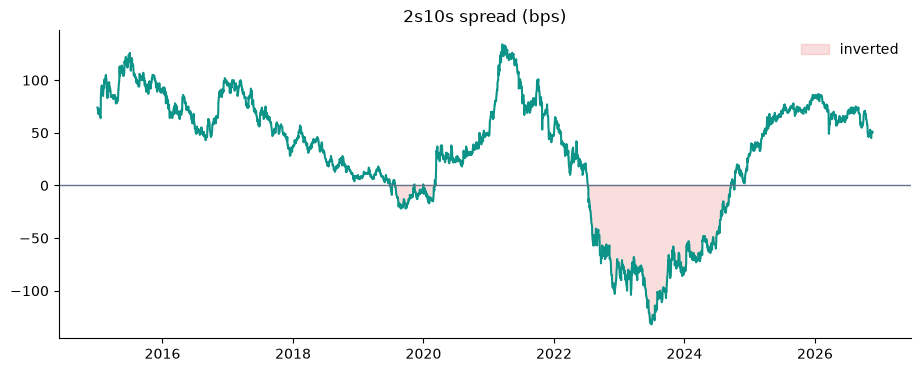

,days,inverted_days,mean_spread_bps
year,,,
2015,250,0,97.2
2016,250,0,69.1
2017,249,0,69.3
2018,250,0,29.2
2019,250,111,-0.4
2020,251,43,24.2
2021,249,0,88.8
2022,248,118,-12.6
2023,248,248,-90.8


In [4]:
yc = q("select * from gold.mart_yield_curve order by obs_date")
fig, ax = plt.subplots()
ax.plot(yc.obs_date, yc.spread_2s10s_bps, color="#0d9488", lw=1.5)
ax.axhline(0, color="#64748b", lw=1)
ax.fill_between(yc.obs_date, yc.spread_2s10s_bps, 0, where=yc.is_inverted, color="#dc2626", alpha=0.15, label="inverted")
ax.set_title("2s10s spread (bps)"); ax.legend(frameon=False); plt.show()
yc.assign(year=pd.to_datetime(yc.obs_date).dt.year).groupby("year").agg(
    days=("obs_date", "count"), inverted_days=("is_inverted", "sum"),
    mean_spread_bps=("spread_2s10s_bps", "mean")).round(1)

## 3. FX: 30-day volatility by pair

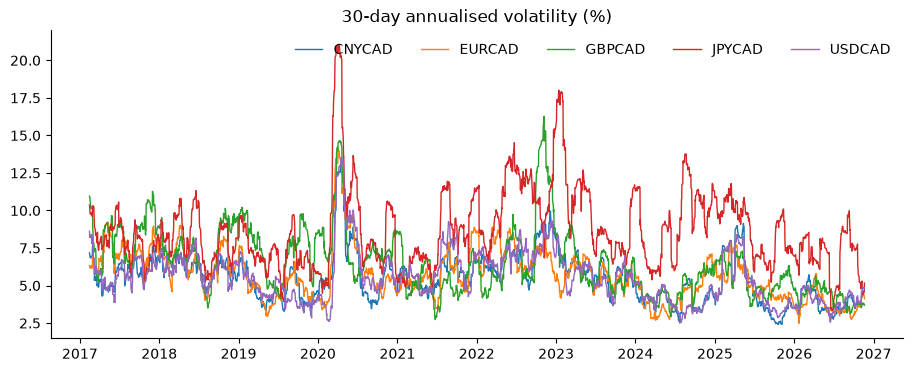

,count,mean,std,min,25%,50%,75%,max
pair,,,,,,,,
CNYCAD,2436.0,5.48,1.60,2.41,4.26,5.43,6.38,12.85
EURCAD,2436.0,5.72,1.73,2.48,4.49,5.57,6.75,13.97
GBPCAD,2436.0,6.50,2.19,2.74,4.85,6.06,7.72,16.28
JPYCAD,2436.0,8.67,2.61,3.36,6.85,8.18,10.05,21.06
USDCAD,2436.0,5.55,1.68,2.53,4.30,5.38,6.55,13.52


In [5]:
fx = q("select pair, obs_date, rate, vol_30d_pct from gold.mart_fx_daily order by obs_date")
fig, ax = plt.subplots()
for pair, g in fx.groupby("pair"):
    ax.plot(g.obs_date, g.vol_30d_pct, lw=1, label=pair)
ax.set_title("30-day annualised volatility (%)"); ax.legend(frameon=False, ncol=5); plt.show()
fx.groupby("pair").vol_30d_pct.describe().round(2)

## 4. Policy rate, inflation and the real policy rate

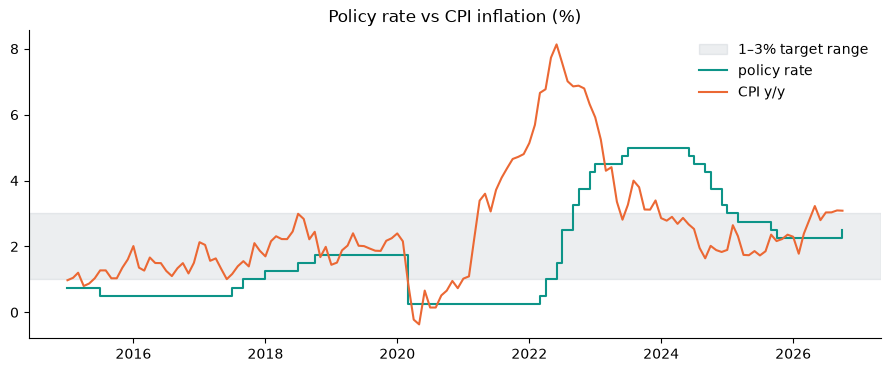

,direction,decisions,total_bps
0,cut,14,-475.0
1,hike,16,625.0


In [6]:
rp = q("select * from gold.mart_real_policy_rate order by month")
fig, ax = plt.subplots()
ax.axhspan(1, 3, color="#64748b", alpha=0.12, label="1–3% target range")
ax.step(rp.month, rp.policy_rate_eom, where="post", color="#0d9488", label="policy rate")
ax.plot(rp.month, rp.cpi_yoy_pct, color="#eb6834", label="CPI y/y")
ax.set_title("Policy rate vs CPI inflation (%)"); ax.legend(frameon=False); plt.show()
q("select direction, count(*) as decisions, sum(change_bps) as total_bps from gold.mart_policy_rate_events group by 1")

In [7]:
rp.real_policy_rate.describe().round(2)

count    142.00
mean      -0.70
std        1.90
min       -6.73
25%       -1.00
50%       -0.54
75%        0.18
max        2.65
Name: real_policy_rate, dtype: float64

## 5. Data quality

Latest run of every control, and the anomaly flags by series.

In [8]:
q("""
select dq_category, status, count(*) as tests
from gold.dq_results
where run_id = (select run_id from gold.dq_results order by run_at desc limit 1)
group by all order by 1, 2
""")

,dq_category,status,tests
0,anomaly,warn,3
1,completeness,pass,4
2,completeness,warn,1
3,freshness,pass,5
4,integrity,pass,76
5,range,pass,7
6,reconciliation,pass,3


In [9]:
q("select series_key, count(*) as anomalies, max(abs(z_score)) as max_abs_z from gold.dq_anomalies group by 1 order by 2 desc")

,series_key,anomalies,max_abs_z
0,CORRA,26,32.40
1,GOC_2Y,7,11.55
2,FX_USDCAD,5,8.05
3,FX_CNYCAD,4,7.01
4,GOC_LONG,4,6.19
5,FX_JPYCAD,3,10.06
6,FX_GBPCAD,2,5.49
7,FX_EURCAD,1,8.24
8,GOC_5Y,1,5.47


In [10]:
q("select * from gold.dq_completeness where missing_periods > 0")

,series_key,category,frequency,first_date,last_date,expected_periods,missing_periods,completeness_pct
0,POLICY_RATE,policy_rate,daily,2015-01-01,2026-11-19,2965,2,99.933


## Takeaways

* The tables above show coverage, inversion periods, FX volatility regimes and the real
  policy rate exactly as stored in the gold layer.
* Anomaly flags cluster around rate decisions and market stress; they are review flags,
  not data errors, which is why the anomaly control has `warn` severity.

In [11]:
con.close()